In [34]:
import pandas as pd

path = "../data/raw/swissgrid/EnergieUebersichtCH-2009.xls"

df = pd.read_excel(
    path,
    sheet_name="Zeitreihen0h15",  # the 15-minute sheet
    usecols=[0, 1],               # only timestamp + end-user consumption
    skiprows=[1],                 # skip the units row ("Zeitstempel", "kWh")
)
df.columns = ["timestamp", "consumption_kwh"]   # short, clean names

df.head()

/tmp/ipykernel_33664/3177261113.py:5: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(


,timestamp,consumption_kwh
0,2009-01-01 00:15:00,1829965.532
1,2009-01-01 00:30:00,1715172.867
2,2009-01-01 00:45:00,1732581.748
3,2009-01-01 01:00:00,1706689.208
4,2009-01-01 01:15:00,1722372.541


In [35]:
print(df.shape)          # (rows, columns)
print(df.dtypes)         # timestamp must be datetime, consumption must be float
print(df.tail())         # look at the END of the file too
print(df.isna().sum())   # missing values per column

(35040, 2)
timestamp          datetime64[us]
consumption_kwh           float64
dtype: object
                timestamp  consumption_kwh
35035 2009-12-31 23:00:00      1594720.846
35036 2009-12-31 23:15:00      1628813.528
35037 2009-12-31 23:30:00      1607250.665
35038 2009-12-31 23:45:00      1607259.462
35039 2010-01-01 00:00:00      1580559.666
timestamp          0
consumption_kwh    0
dtype: int64


In [36]:
df["timestamp"].diff().value_counts()

timestamp
0 days 00:15:00      35037
0 days 01:15:00          1
-1 days +23:15:00        1
Name: count, dtype: int64

In [37]:
df[df["timestamp"].duplicated(keep=False)]

,timestamp,consumption_kwh
28516,2009-10-25 02:15:00,1245695.988
28517,2009-10-25 02:30:00,1220140.501
28518,2009-10-25 02:45:00,1216039.268
28519,2009-10-25 03:00:00,1199177.537
28520,2009-10-25 02:15:00,1185373.163
28521,2009-10-25 02:30:00,1171522.830
28522,2009-10-25 02:45:00,1142847.659
28523,2009-10-25 03:00:00,1132867.703


In [38]:
# shift back 15 min so each value belongs to the day it was consumed
df["start"] = df["timestamp"] - pd.Timedelta(minutes=15)
df["date"] = df["start"].dt.date

counts = df.groupby("date").size()   # number of values per day
counts[counts != 96]                 # show only the abnormal days

date
2009-03-29     92
2009-10-25    100
dtype: int64

In [39]:
from pathlib import Path

files = sorted(Path("../data/raw/swissgrid").glob("EnergieUebersichtCH-*.xls*"))
print(len(files), "files found")

parts = []
for f in files:
    part = pd.read_excel(
        f,
        sheet_name="Zeitreihen0h15",
        usecols=[0, 1],
        skiprows=[1],
        engine="calamine",
    )
    part.columns = ["timestamp", "consumption_kwh"]
    part["source_file"] = f.name        # remember where each row came from
    parts.append(part)
    print(f"{f.name}: {len(part)} rows")

raw = pd.concat(parts, ignore_index=True)   # stack all years into one table
raw.shape

17 files found
EnergieUebersichtCH-2009.xls: 35040 rows
EnergieUebersichtCH-2010.xls: 35040 rows
EnergieUebersichtCH-2011.xls: 35040 rows
EnergieUebersichtCH-2012.xls: 35136 rows
EnergieUebersichtCH-2013.xls: 35040 rows
EnergieUebersichtCH-2014.xls: 35040 rows
EnergieUebersichtCH-2015.xls: 35040 rows
EnergieUebersichtCH-2016.xls: 35136 rows
EnergieUebersichtCH-2017.xls: 35040 rows
EnergieUebersichtCH-2018.xls: 35040 rows
EnergieUebersichtCH-2019.xls: 35040 rows
EnergieUebersichtCH-2020.xlsx: 35136 rows
EnergieUebersichtCH-2021.xlsx: 35040 rows
EnergieUebersichtCH-2022.xlsx: 35040 rows
EnergieUebersichtCH-2023.xlsx: 35040 rows
EnergieUebersichtCH-2024.xlsx: 35136 rows
EnergieUebersichtCH-2025.xlsx: 35040 rows


(596064, 3)

In [40]:
print(raw.dtypes)
print(raw.isna().sum())
print("first:", raw["timestamp"].iloc[0], "| last:", raw["timestamp"].iloc[-1])

# all gaps between consecutive rows, across ALL years
# raw["timestamp"].diff().value_counts()

timestamp           object
consumption_kwh    float64
source_file            str
dtype: object
timestamp          0
consumption_kwh    0
source_file        0
dtype: int64
first: 2009-01-01 00:15:00 | last: 31.12.2025 23:45


In [41]:
raw.to_csv("../data/processed/swissgrid_15min_raw.csv", index=False)

In [42]:
# the Python type of each timestamp value (Timestamp or str)
raw["ts_type"] = raw["timestamp"].map(lambda x: type(x).__name__)

raw.groupby("source_file")["ts_type"].value_counts()

source_file                    ts_type  
EnergieUebersichtCH-2009.xls   Timestamp    35040
EnergieUebersichtCH-2010.xls   Timestamp    35040
EnergieUebersichtCH-2011.xls   Timestamp    35040
EnergieUebersichtCH-2012.xls   Timestamp    35136
EnergieUebersichtCH-2013.xls   Timestamp    35040
EnergieUebersichtCH-2014.xls   Timestamp    35040
EnergieUebersichtCH-2015.xls   Timestamp    35040
EnergieUebersichtCH-2016.xls   Timestamp    35136
EnergieUebersichtCH-2017.xls   Timestamp    35040
EnergieUebersichtCH-2018.xls   Timestamp    35040
EnergieUebersichtCH-2019.xls   Timestamp    35040
EnergieUebersichtCH-2020.xlsx  Timestamp    35136
EnergieUebersichtCH-2021.xlsx  str          35040
EnergieUebersichtCH-2022.xlsx  str          35040
EnergieUebersichtCH-2023.xlsx  str          35040
EnergieUebersichtCH-2024.xlsx  str          35136
EnergieUebersichtCH-2025.xlsx  str          35040
Name: count, dtype: int64

In [43]:
raw.groupby("source_file")["timestamp"].agg(["first", "last"])

,first,last
source_file,,
EnergieUebersichtCH-2009.xls,2009-01-01 00:15:00,2010-01-01 00:00:00
EnergieUebersichtCH-2010.xls,2010-01-01 00:15:00,2011-01-01 00:00:00
EnergieUebersichtCH-2011.xls,2011-01-01 00:15:00,2012-01-01 00:00:00
EnergieUebersichtCH-2012.xls,2012-01-01 00:15:00,2013-01-01 00:00:00
EnergieUebersichtCH-2013.xls,2013-01-01 00:15:00,2014-01-01 00:00:00
EnergieUebersichtCH-2014.xls,2014-01-01 00:15:00,2015-01-01 00:00:00
EnergieUebersichtCH-2015.xls,2015-01-01 00:15:00,2016-01-01 00:00:00
EnergieUebersichtCH-2016.xls,2016-01-01 00:15:00,2017-01-01 00:00:00
EnergieUebersichtCH-2017.xls,2017-01-01 00:15:00,2018-01-01 00:00:00


In [44]:
for name in ["EnergieUebersichtCH-2024.xlsx", "EnergieUebersichtCH-2025.xlsx"]:
    year = raw[raw["source_file"] == name]
    print(name)
    print(year.loc[year["timestamp"].duplicated(keep=False), "timestamp"].tolist())

EnergieUebersichtCH-2024.xlsx
['27.10.2024 02:00', '27.10.2024 02:15', '27.10.2024 02:30', '27.10.2024 02:45', '27.10.2024 02:00', '27.10.2024 02:15', '27.10.2024 02:30', '27.10.2024 02:45']
EnergieUebersichtCH-2025.xlsx
['26.10.2025 02:00', '26.10.2025 02:15', '26.10.2025 02:30', '26.10.2025 02:45', '26.10.2025 02:00', '26.10.2025 02:15', '26.10.2025 02:30', '26.10.2025 02:45']


In [45]:
is_text = raw["ts_type"] == "str"

# parse only the text values, with their exact format: day.month.year hour:minute
raw.loc[is_text, "timestamp"] = pd.to_datetime(
    raw.loc[is_text, "timestamp"], format="%d.%m.%Y %H:%M"
)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])   # make the whole column datetime
raw = raw.drop(columns="ts_type")
raw.dtypes

timestamp          datetime64[us]
consumption_kwh           float64
source_file                   str
dtype: object

In [46]:
is_2025 = raw["source_file"] == "EnergieUebersichtCH-2025.xlsx"
raw.loc[is_2025, "timestamp"] += pd.Timedelta(minutes=15)

In [47]:
raw.loc[is_2025, "timestamp"].iloc[[0, -1]]   # first and last row

561024   2025-01-01 00:15:00
596063   2026-01-01 00:00:00
Name: timestamp, dtype: datetime64[us]

In [48]:
raw["timestamp"].diff().value_counts()

timestamp
0 days 00:15:00      596029
0 days 01:15:00          17
-1 days +23:15:00        17
Name: count, dtype: int64

In [49]:
raw.to_csv("../data/processed/swissgrid_15min_raw.csv", index=False)

In [50]:
for day in ["2024-03-31", "2025-03-30"]:
    m = raw["timestamp"].between(f"{day} 01:30", f"{day} 03:30")
    print(day, raw.loc[m, "timestamp"].dt.strftime("%H:%M").tolist())

2024-03-31 ['01:30', '01:45', '03:00', '03:15', '03:30']
2025-03-30 ['01:30', '01:45', '02:00', '03:15', '03:30']


## Part 2 – Aggregation to daily consumption

In [51]:
df15 = raw.copy()

# date when each quarter-hour was consumed (end label minus 15 min)
df15["date"] = (df15["timestamp"] - pd.Timedelta(minutes=15)).dt.normalize()

daily = df15.groupby("date").agg(
    n_values=("consumption_kwh", "size"),   # how many quarter-hours that day
    mean_kwh=("consumption_kwh", "mean"),   # mean per quarter-hour
)

# 24-hour equivalent, converted from kWh to GWh (1 GWh = 1,000,000 kWh)
daily["consumption_gwh"] = daily["mean_kwh"] * 96 / 1e6
daily.head()

,n_values,mean_kwh,consumption_gwh
date,,,
2009-01-01,96,1.508486e+06,144.814633
2009-01-02,96,1.606978e+06,154.269911
2009-01-03,96,1.676302e+06,160.924955
2009-01-04,96,1.610815e+06,154.638229
2009-01-05,96,1.958580e+06,188.023687


In [52]:
print("number of days:", len(daily))
print(daily["n_values"].value_counts())

# compare with the complete calendar
full_range = pd.date_range("2009-01-01", "2025-12-31", freq="D")
missing_days = full_range.difference(daily.index)
print("missing days:", len(missing_days))

number of days: 6209
n_values
96     6175
92       17
100      17
Name: count, dtype: int64
missing days: 0


count    6209.000000
mean      153.738842
std        23.124095
min        98.528614
25%       138.407608
50%       152.244419
75%       169.516521
max       222.503925
Name: consumption_gwh, dtype: float64


<Axes: title={'center': 'Daily electricity consumption, Switzerland (GWh)'}, xlabel='date'>

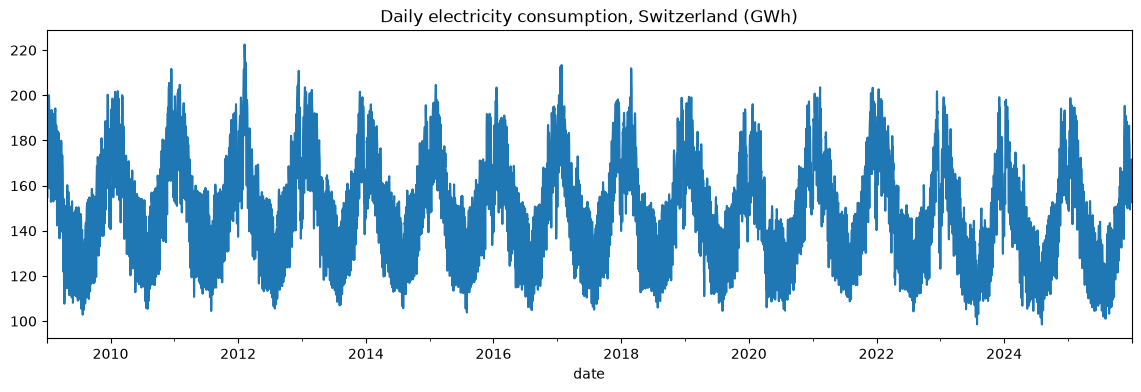

In [53]:
print(daily["consumption_gwh"].describe())
daily["consumption_gwh"].plot(figsize=(14, 4), title="Daily electricity consumption, Switzerland (GWh)")

## Look at the extremes

In [54]:
daily["weekday"] = daily.index.day_name()

print("Lowest days:")
print(daily.nsmallest(5, "consumption_gwh")[["consumption_gwh", "weekday"]])
print("\nHighest days:")
print(daily.nlargest(5, "consumption_gwh")[["consumption_gwh", "weekday"]])

Lowest days:
            consumption_gwh weekday
date                               
2024-08-04        98.528614  Sunday
2023-07-30        98.608849  Sunday
2025-08-03       101.075536  Sunday
2024-07-28       101.605664  Sunday
2023-07-23       101.885492  Sunday

Highest days:
            consumption_gwh    weekday
date                                  
2012-02-07       222.503925    Tuesday
2012-02-08       219.701151  Wednesday
2012-02-09       216.420641   Thursday
2012-02-10       216.140561     Friday
2012-02-06       215.982064     Monday


<Axes: title={'center': 'January 2019 – weekly cycle'}, xlabel='date'>

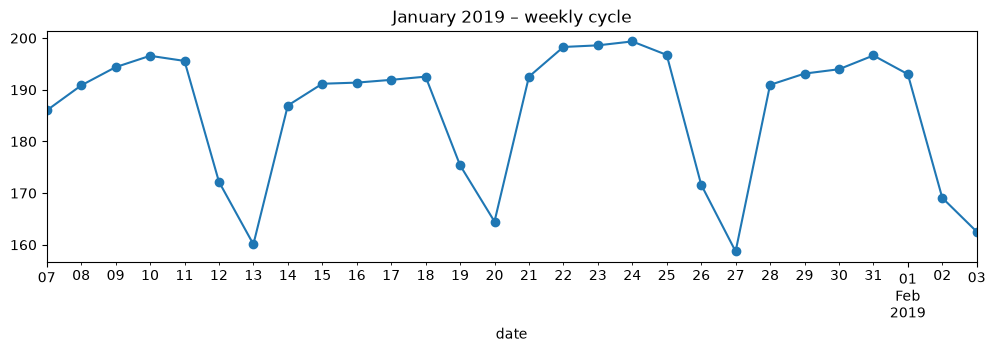

In [55]:
daily.loc["2019-01-07":"2019-02-03", "consumption_gwh"].plot(
    figsize=(12, 3), marker="o", title="January 2019 – weekly cycle"
)

/tmp/ipykernel_33664/3038815334.py:6: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  ax.plot(s.index.dayofyear, s.values, label=str(year))
/tmp/ipykernel_33664/3038815334.py:6: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  ax.plot(s.index.dayofyear, s.values, label=str(year))


Text(0.5, 1.0, 'Spring 2019 vs spring 2020 (COVID lockdown from mid-March 2020)')

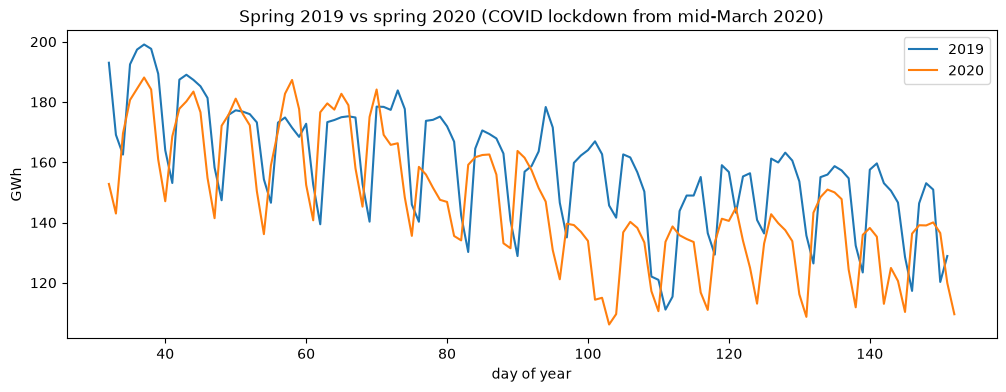

In [56]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
for year in [2019, 2020]:
    s = daily.loc[f"{year}-02-01":f"{year}-05-31", "consumption_gwh"]
    ax.plot(s.index.dayofyear, s.values, label=str(year))
ax.set_xlabel("day of year"); ax.set_ylabel("GWh"); ax.legend()
ax.set_title("Spring 2019 vs spring 2020 (COVID lockdown from mid-March 2020)")

In [57]:
daily[["consumption_gwh", "n_values"]].to_csv("../data/processed/swissgrid_daily.csv")